<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_04_groups_and_whole_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 4 · Groups and the whole network

*M2 Network Analysis · Mapping collaboration with networks*

**The story so far.** Part 3 found who is central in the inventor core. Now we describe the network as a whole.

> **Today's question:** Is the inventor core dense or sparse, clustered or random, a 'small world'? And can we find its communities?

**You will learn to**

1. Compute graph-level measures: **density**, **transitivity**, **diameter**, **average path length**, **assortativity**.
2. Judge a value by comparing it with **random networks** of the same size.
3. Explain **modularity** and find communities with the **Louvain** method.
4. Use the **resolution** parameter to zoom in and out on communities.

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

**Rebuild the network from Part 2:**

In [ ]:
from networkx.algorithms import bipartite

URL = ("https://raw.githubusercontent.com/hamidb201214-svg/Lectures/"
       "refs/heads/main/data/epo_inventors_clean.csv")
df = pd.read_csv(URL, low_memory=False)                 # the file is UTF-8 (keeps Ø, Å, Æ)
df = df.drop_duplicates(["inv_name", "appln_id"])       # one row per inventor x application

# Two-mode network: inventors <-> applications  (built step by step in Part 2)
B = nx.Graph()
B.add_nodes_from(df["inv_name"].unique(), bipartite="inventor")
B.add_nodes_from(df["appln_id"].unique(), bipartite="application")
B.add_edges_from(df[["inv_name", "appln_id"]].itertuples(index=False, name=None))

def ordered(H):
    """Same node and edge order on every computer, so layouts and communities are reproducible."""
    R = nx.Graph()
    R.add_nodes_from(sorted(H.nodes(data=True)))
    R.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in H.edges(data=True)))
    return R

# One-mode projection: inventor -- inventor, weight = number of shared applications
G = ordered(bipartite.weighted_projected_graph(B, df["inv_name"].unique()))

# The "core": the largest connected group of inventors
core = ordered(G.subgraph(max(nx.connected_components(G), key=len)))
pos = nx.spring_layout(core, seed=7, k=0.25)             # fixed seed = same picture every time

print("Full network:", G)
print("Core        :", core)

Full network: Graph with 3744 nodes and 7632 edges
Core        : Graph with 205 nodes and 814 edges


In [ ]:
# The 7-node graph from the lecture slides (the one we worked through by hand)
toy = nx.Graph([("A", "B"), ("A", "C"), ("A", "D"), ("B", "C"), ("B", "D"),
                ("C", "D"), ("C", "E"), ("D", "E"), ("E", "F"), ("F", "G")])
toy_pos = {"A": (0, 1), "B": (0, -1), "C": (1.3, 1), "D": (1.3, -1),
           "E": (2.6, 0), "F": (3.9, 0), "G": (5.2, 0)}

## 1. Graph-level measures

| measure | formula | question it answers |
|---|---|---|
| density | $\frac{2m}{n(n-1)}$ | what share of all possible ties exist? |
| transitivity | $\frac{3 \times \text{triangles}}{\text{connected triples}}$ | are my partners' partners also my partners? |
| average clustering | mean of local $C_i$ | the same, averaged node by node |
| diameter | $\max d(i,j)$ | how far apart are the two most distant nodes? |
| average path length | mean $d(i,j)$ | how many steps, on average, between two nodes? |
| degree assortativity | correlation of degrees at both ends of a tie | do hubs connect to hubs? |

First the hand-check on the 7-node graph, then the core:

In [ ]:
def describe(H):
    return pd.Series({
        "nodes": H.number_of_nodes(),
        "edges": H.number_of_edges(),
        "density": nx.density(H),
        "transitivity": nx.transitivity(H),
        "avg clustering": nx.average_clustering(H),
        "diameter": nx.diameter(H),
        "avg path length": nx.average_shortest_path_length(H),
        "degree assortativity": nx.degree_assortativity_coefficient(H),
    })

pd.DataFrame({"7-node graph": describe(toy), "inventor core": describe(core)}).round(3)

,7-node graph,inventor core
nodes,7.000,205.000
edges,10.000,814.000
density,0.476,0.039
transitivity,0.682,0.340
avg clustering,0.524,0.718
diameter,4.000,7.000
avg path length,1.905,3.074
degree assortativity,0.394,-0.057


Toy graph, as in the slides: density 10/21 = 0.476, transitivity 15/22 = 0.682, diameter 4, average path 40/21 = 1.905,
assortativity 0.394.

### 🔎 Reading the core
- **Density ≈ 0.04**: only about 4% of all possible pairs collaborate — sparse, as almost all real networks are.
- **Transitivity ≈ 0.34, average clustering ≈ 0.72**: very cliquish. (Remember Part 2: every team becomes a clique.)
  The two differ because small inventors sit in tight teams (local C = 1), while hubs have many partners who do not know each other.
- **Average path ≈ 3**: any two inventors are about three collaborations apart.
- **Degree assortativity ≈ 0**: hubs do not especially seek out other hubs (unlike the toy graph, +0.39).

But is 0.34 *high*? A number only means something against a **benchmark**.

## 2. Compared to what? Random benchmarks

We generate random networks with the **same number of nodes and edges**:
- **Erdős–Rényi** $G(n, m)$: ties placed completely at random.
- **Configuration model**: random, but every node keeps its degree (so hubs stay hubs).

In [ ]:
def summary(H):
    H = H.subgraph(max(nx.connected_components(H), key=len))   # paths need a connected graph
    return {"transitivity": nx.transitivity(H), "avg path length": nx.average_shortest_path_length(H)}

def simple(H):
    H = nx.Graph(H)                                   # merge parallel edges
    H.remove_edges_from(nx.selfloop_edges(H))         # drop self-loops
    return H

n, m = core.number_of_nodes(), core.number_of_edges()
er  = pd.DataFrame([summary(nx.gnm_random_graph(n, m, seed=s)) for s in range(20)]).mean()
cfg = pd.DataFrame([summary(simple(nx.configuration_model([d for _, d in core.degree()], seed=s)))
                    for s in range(20)]).mean()

bench = pd.DataFrame({"inventor core": summary(core), "random G(n,m)": er, "configuration model": cfg}).round(3)
bench

,inventor core,"random G(n,m)",configuration model
transitivity,0.340,0.039,0.077
avg path length,3.074,2.786,2.804


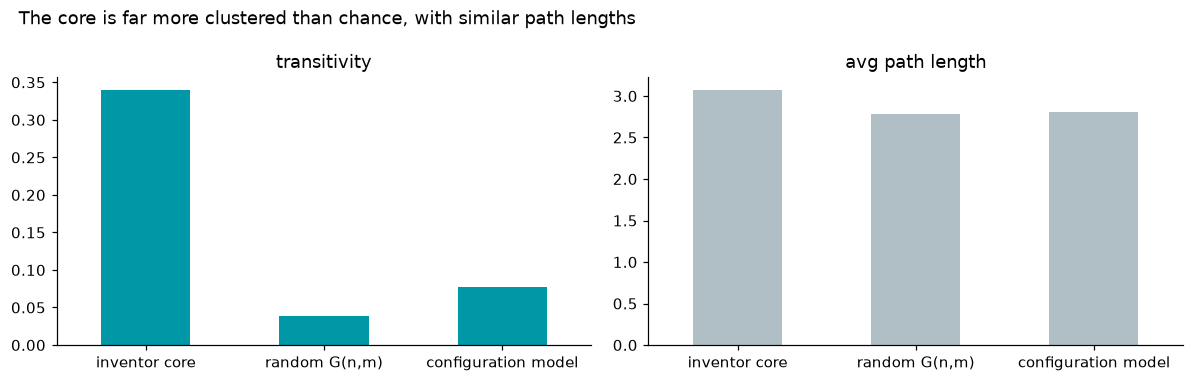

In [ ]:
ax = bench.T.plot.bar(subplots=True, layout=(1, 2), figsize=(11, 3.5), legend=False,
                      color=[TEAL, GREY, GREY], rot=0)
plt.suptitle("The core is far more clustered than chance, with similar path lengths", x=0.02, ha="left")
plt.tight_layout(); plt.show()

### 🔎 A small world
The core has **much more clustering** than random networks of the same size, but **similar short paths**.
That combination is called a **small world** (Watts & Strogatz, 1998): tight teams, connected by a few
brokers (the high-betweenness inventors from Part 3).

What if everything were perfectly regular or random? The four extreme cases from the lecture:

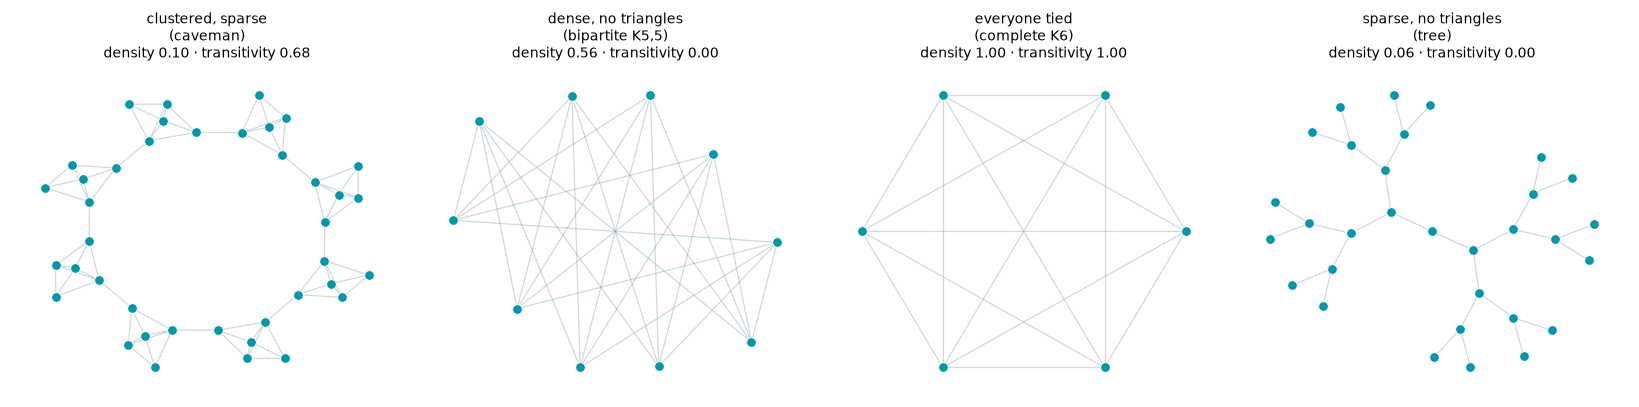

In [ ]:
cases = {
    "clustered, sparse\n(caveman)": nx.connected_caveman_graph(8, 5),
    "dense, no triangles\n(bipartite K5,5)": nx.complete_bipartite_graph(5, 5),
    "everyone tied\n(complete K6)": nx.complete_graph(6),
    "sparse, no triangles\n(tree)": nx.balanced_tree(2, 4),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (name, H) in zip(axes, cases.items()):
    draw(H, nx.kamada_kawai_layout(H), ax=ax, node_size=40, width=0.8)
    ax.set_title(f"{name}\ndensity {nx.density(H):.2f} · transitivity {nx.transitivity(H):.2f}", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Communities

A **community** is a group of nodes with many ties inside and few ties to the outside.

### 3.1 Modularity: scoring a partition

$$Q = \sum_c \left[ \frac{L_c}{m} - \lambda \left( \frac{d_c}{2m} \right)^2 \right]$$

- $L_c/m$ = share of all ties that fall **inside** community $c$ (what we observe)
- $(d_c / 2m)^2$ = share we would **expect by chance** given the degrees ($d_c$ = sum of degrees in $c$)
- $\lambda$ = **resolution** (1 = standard modularity)

$Q > 0$: more ties inside the groups than chance. Check the lecture example {ABCD}{EFG}:

In [ ]:
L1, d1 = 6, 3 + 3 + 4 + 4        # community {A,B,C,D}: 6 inner ties, degree sum 14
L2, d2 = 2, 3 + 2 + 1            # community {E,F,G}:   2 inner ties, degree sum 6
m_toy = toy.number_of_edges()
Q_hand = (L1 / m_toy - (d1 / (2 * m_toy)) ** 2) + (L2 / m_toy - (d2 / (2 * m_toy)) ** 2)

print("by hand  :", round(Q_hand, 3))
print("networkx :", round(nx.community.modularity(toy, [{"A", "B", "C", "D"}, {"E", "F", "G"}]), 3))

by hand  : 0.22
networkx : 0.22


### 3.2 The Louvain method
Trying every possible partition is impossible. **Louvain** climbs to a high $Q$ greedily:

1. Start with every node in its own community.
2. Move each node to the neighbouring community that **raises Q the most** (if any).
3. When no move helps, **merge** each community into a super-node and repeat on the smaller network.
4. Stop when Q no longer improves.

(`networkx` ships Louvain; the `python-louvain` package's `community_louvain.best_partition` does the same.)

In [ ]:
communities = nx.community.louvain_communities(core, seed=42)
communities = sorted(communities, key=len, reverse=True)
print(len(communities), "communities, sizes:", [len(c) for c in communities])
print("modularity Q =", round(nx.community.modularity(core, communities), 3))

10 communities, sizes: [38, 31, 27, 23, 22, 17, 16, 15, 10, 6]
modularity Q = 0.608


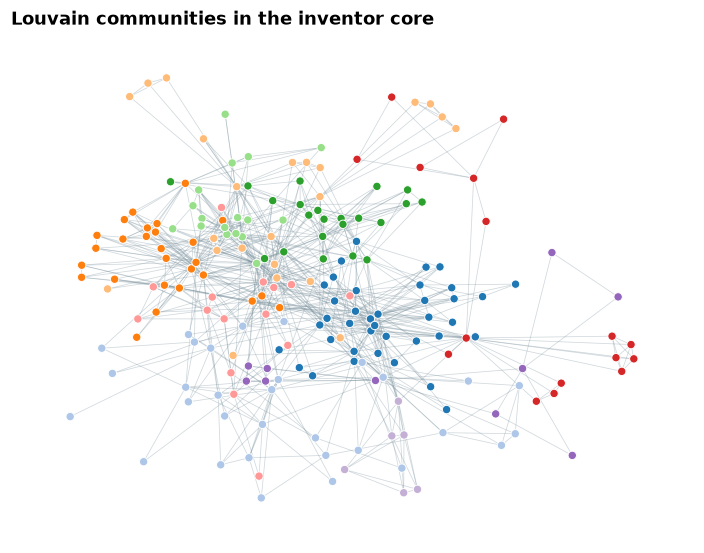

In [ ]:
membership = {n: i for i, c in enumerate(communities) for n in c}
draw(core, pos, node_size=30, node_color=community_colors(core, membership),
     width=0.5, title="Louvain communities in the inventor core")
plt.show()

**What are these communities?** The algorithm only saw ties, never addresses. So let us look at who is in them:
the most central member and the inventors' cities.

In [ ]:
city = df.drop_duplicates("inv_name").set_index("inv_name")["city"]
deg = dict(core.degree())
for i, c in enumerate(communities[:4]):
    leader = max(sorted(c), key=deg.get)
    print(f"community {i} ({len(c)} inventors), most central: {leader.title()}")
    print("    cities:", city.reindex(sorted(c)).value_counts().head(4).to_dict())

community 0 (38 inventors), most central: Caporal Del Barrio, Samantha
    cities: {'Aalborg': 6, 'Espoo': 4, 'Munich': 4, 'Kempele': 3}
community 1 (31 inventors), most central: Kovács, István Zsolt
    cities: {'Aalborg': 9, 'Munich': 3, 'Gistrup': 2, 'Palaiseau': 1}
community 2 (27 inventors), most central: Sabouri-Sichani, Faranaz
    cities: {'Bangalore': 7, 'Aalborg': 4, 'Munich': 4, 'Espoo': 2}
community 3 (23 inventors), most central: Li, Zexian
    cities: {'Espoo': 5, 'Aalborg': 5, 'Norresundby': 2, 'Wroclaw': 2}


Communities are **not** simply cities: inventors in Aalborg, Munich, Espoo and Bangalore end up in the same
communities. These are probably R&D teams of the same multinational firms, spread over several sites —
a structure we could never have found with a `groupby("city")`.

### 3.3 The resolution parameter: zooming in and out

$\lambda < 1$ → fewer, larger communities. $\lambda > 1$ → more, smaller communities. There is no single
"true" number of communities; the resolution is a lens.

In [ ]:
rows = []
for lam in [0.2, 0.5, 1, 2, 4]:
    cs = nx.community.louvain_communities(core, resolution=lam, seed=42)
    rows.append({"resolution": lam, "communities": len(cs),
                 "largest": max(len(c) for c in cs),
                 "Q (standard)": round(nx.community.modularity(core, cs), 3)})
pd.DataFrame(rows)

,resolution,communities,largest,Q (standard)
0,0.2,3,132,0.389
1,0.5,6,65,0.561
2,1.0,10,38,0.608
3,2.0,16,23,0.583
4,4.0,22,16,0.517


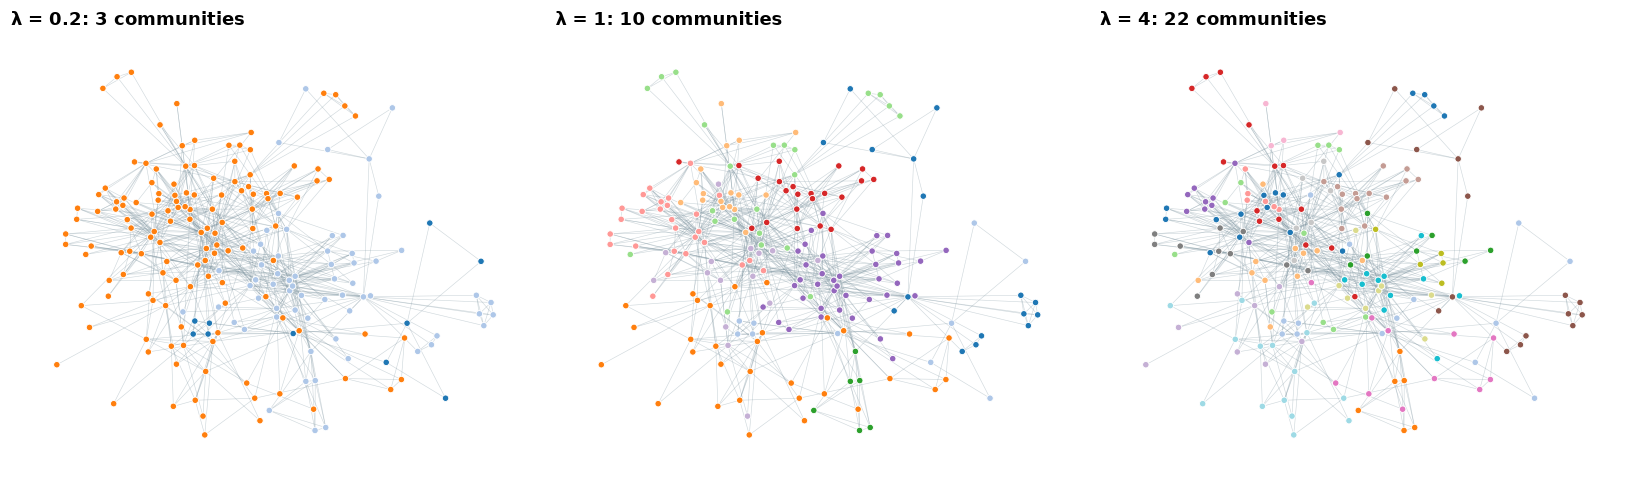

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, lam in zip(axes, [0.2, 1, 4]):
    cs = nx.community.louvain_communities(core, resolution=lam, seed=42)
    mem = {n: i for i, c in enumerate(cs) for n in c}
    draw(core, pos, ax=ax, node_size=18, node_color=community_colors(core, mem),
         width=0.4, title=f"λ = {lam}: {len(cs)} communities")
plt.tight_layout(); plt.show()

## 🧑‍💻 Your turn

1. Run Louvain with five different `seed` values. Do the number of communities and Q change? Why might they?
2. Is the core **assortative** by degree? Interpret the sign of `nx.degree_assortativity_coefficient(core)`.
3. Compute the measures of Section 1 for the *second-largest* component. Is it also a small world?

In [ ]:
# your code here

## ✅ Key takeaways
- Density, transitivity and path length describe the **whole network**; judge them against **random benchmarks**.
- The inventor core is a **small world**: highly clustered, yet short paths.
- **Modularity** compares ties inside groups with what chance predicts; **Louvain** finds a high-Q partition fast.
- The **resolution** λ decides how coarse or fine the communities are.

**Next → Part 5:** zoom out from inventors to **countries**.